# 📡 Churn Prediction — Clienti TIM

Pipeline completa di Machine Learning per predire il churn dei clienti TIM.

## Struttura del notebook
1. Setup & caricamento dati
2. Costruzione del target (variabile dipendente)
3. Analisi esplorativa (EDA)
4. Feature engineering
5. Preprocessing
6. Modellazione e valutazione
7. Interpretabilità con SHAP
8. Segmentazione rischio & Export
9. Conclusioni

## 1. Setup & Caricamento Dati

In [56]:
# Installa dipendenze aggiuntive (se necessario)
!pip install -q xgboost lightgbm shap imbalanced-learn

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')

print('✅ Librerie importate correttamente')

✅ Librerie importate correttamente


In [58]:
# ─── CARICA I FILE (adatta i path se necessario) ───
# Se usi Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# master_path = '/content/drive/MyDrive/TIM/master_table.csv'
# target_path = '/content/drive/MyDrive/TIM/target_table.csv'

# Se carichi direttamente su Colab (File > Upload):
master_path = 'master_table.csv'
target_path = 'target_table.csv'

master = pd.read_csv(master_path, sep=';')
target = pd.read_csv(target_path, sep=';')

print(f'Master table: {master.shape[0]:,} righe × {master.shape[1]} colonne')
print(f'Target table: {target.shape[0]:,} righe × {target.shape[1]} colonne')
master.head(3)

Master table: 200,755 righe × 56 colonne
Target table: 76,921 righe × 2 colonne


,id_linea,partition_date,data_prima_attivazione_linea,data_att_linea,des_causale_attivazione_agg,provincia_fattura,regione_fattura,provincia_impianto,regione_impianto,area_geografica_impianto,...,mean_nc_fisso_altri_operatori_m1,mean_nc_fisso_altri_operatori_m2,mean_nc_mobile_altri_operatori_m0,mean_nc_mobile_altri_operatori_m1,mean_nc_mobile_altri_operatori_m2,residenza_provincia,nazione_nascita,provincia_nascita,sesso,eta_cliente
0,001336E63ACCBBC458A028085E15A299,2023-08-31,1981-12-01T00:00:00.000+01:00,1981-12-01T00:00:00.000+01:00,variazione,CATANZARO,CALABRIA,CATANZARO,CALABRIA,sud_isole,...,0.0,0.0,1.0,0.0,0.0,CATANZARO,ITALIA,CATANZARO,M,87.0
1,002EB6FB8F4D97B92CCACE5A1C0E983C,2023-08-31,1982-04-20T00:00:00.000+02:00,1982-04-20T00:00:00.000+02:00,variazione,MODENA,EMILIA-ROMAGNA,MODENA,EMILIA-ROMAGNA,centro_nord,...,0.08333333333333333,0.18181818181818182,0.72,0.2916666666666667,0.18181818181818182,MODENA,ITALIA,MODENA,M,83.0
2,00BCBAA6B07802BDF3C88BE1B9E8606E,2023-08-31,2020-01-20T15:19:54.000+01:00,2020-01-20T15:19:54.000+01:00,attivazione,PORDENONE,FRIULI-VENEZIA GIULIA,PORDENONE,FRIULI-VENEZIA GIULIA,altro,...,0.5,0.09523809523809523,1.1363636363636365,1.2777777777777777,0.9523809523809523,PORDENONE,ITALIA,AGRIGENTO,M,73.0


In [59]:
# Fix colonne ADSL lette come stringa (47 righe header duplicate nel CSV)
ADSL_COLS = [
    'mean_downlink_adsl_m0','mean_downlink_adsl_m1','mean_downlink_adsl_m2',
    'mean_uplink_adsl_m0','mean_uplink_adsl_m1','mean_uplink_adsl_m2'
]
for c in ADSL_COLS + ['arpu_offerta_m0','arpu_tot_m0','eta_cliente']:
    master[c] = pd.to_numeric(master[c], errors='coerce')

In [60]:
# 2.218 id_linea duplicati → rimuovi prima di tutto il resto
print(f'Righe prima dedup: {len(master):,}')
master = master.drop_duplicates(subset='id_linea', keep='first')
print(f'Righe dopo dedup:  {len(master):,}')

Righe prima dedup: 200,755
Righe dopo dedup:  198,537


## 2. Costruzione della Variabile Target (Churn)

Un cliente è **churn = 1** se il suo `id_linea` compare nella target table (ha cessato il contratto).

Clienti totali:      198,537
Churn (1):           76,873  (38.7%)
Non churn (0):       121,664  (61.3%)


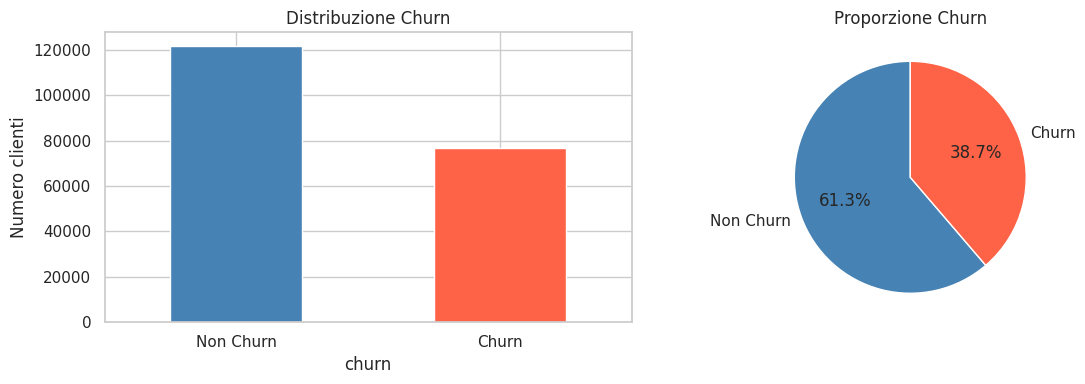


⚠️  Nota: il dataset è sbilanciato (~39% churn). Useremo tecniche apposite.


In [61]:
# Crea variabile target binaria
churn_ids = set(target['id_linea'])
master['churn'] = master['id_linea'].isin(churn_ids).astype(int)

# Statistiche churn
churn_counts = master['churn'].value_counts()
churn_rate = master['churn'].mean() * 100
print(f'Clienti totali:      {len(master):,}')
print(f'Churn (1):           {churn_counts[1]:,}  ({churn_rate:.1f}%)')
print(f'Non churn (0):       {churn_counts[0]:,}  ({100-churn_rate:.1f}%)')

# Visualizzazione
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
churn_counts.plot.bar(ax=ax[0], color=['steelblue','tomato'], edgecolor='white')
ax[0].set_title('Distribuzione Churn')
ax[0].set_xticklabels(['Non Churn', 'Churn'], rotation=0)
ax[0].set_ylabel('Numero clienti')

ax[1].pie(churn_counts, labels=['Non Churn', 'Churn'],
          autopct='%1.1f%%', colors=['steelblue','tomato'], startangle=90)
ax[1].set_title('Proporzione Churn')
plt.tight_layout()
plt.show()

print('\n⚠️  Nota: il dataset è sbilanciato (~39% churn). Useremo tecniche apposite.')

## 3. Analisi Esplorativa (EDA)

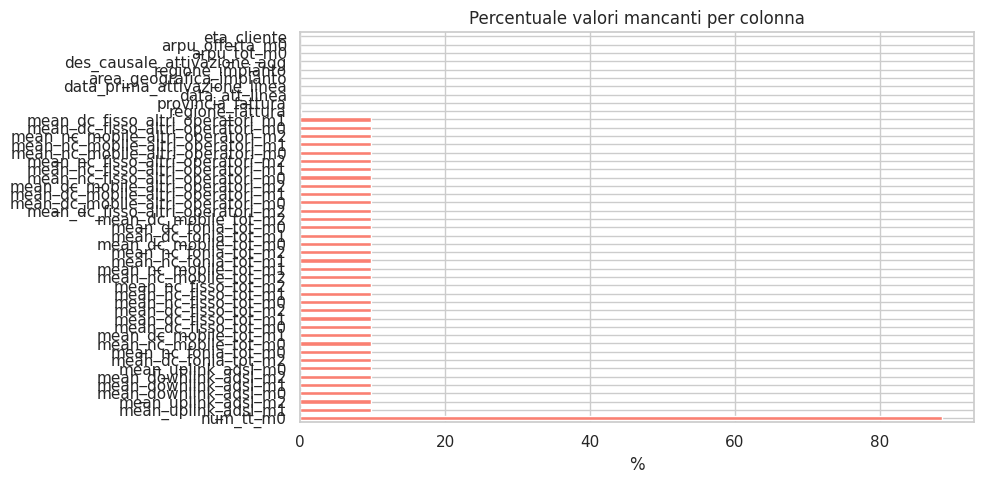

Colonne con > 80% null:
num_tt_m0    88.546719
dtype: float64


In [62]:
# Valori mancanti
null_pct = (master.isnull().sum() / len(master) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

plt.figure(figsize=(10, 5))
null_pct.plot.barh(color='salmon')
plt.title('Percentuale valori mancanti per colonna')
plt.xlabel('%')
plt.tight_layout()
plt.show()

print('Colonne con > 80% null:')
print(null_pct[null_pct > 80])

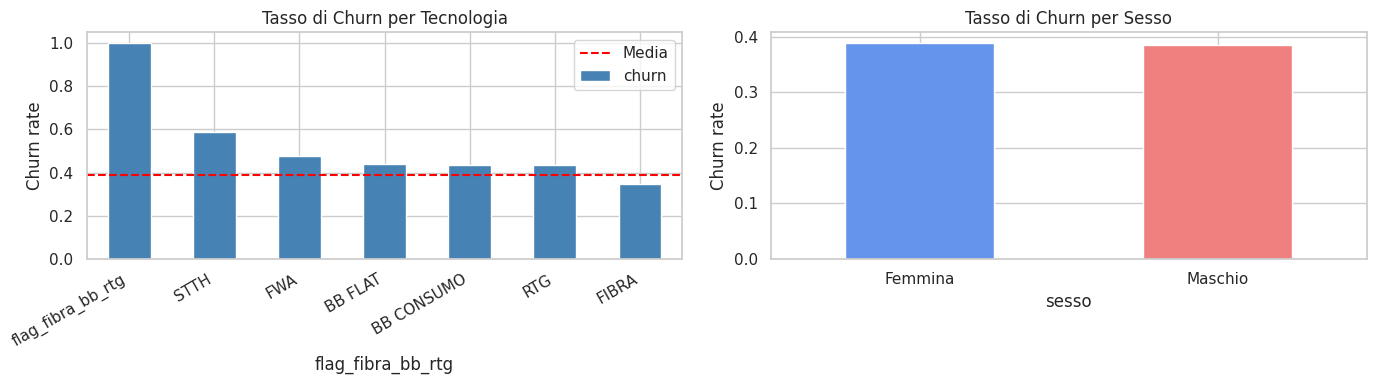

In [63]:
# Churn per tecnologia
tech_churn = master.groupby('flag_fibra_bb_rtg')['churn'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tech_churn.plot.bar(ax=ax[0], color='steelblue', edgecolor='white')
ax[0].set_title('Tasso di Churn per Tecnologia')
ax[0].set_ylabel('Churn rate')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=30, ha='right')
ax[0].axhline(y=master['churn'].mean(), color='red', linestyle='--', label='Media')
ax[0].legend()

# Churn per sesso
sesso_clean = master[master['sesso'].isin(['M', 'F'])]
sesso_churn = sesso_clean.groupby('sesso')['churn'].mean()
sesso_churn.plot.bar(ax=ax[1], color=['cornflowerblue', 'lightcoral'], edgecolor='white')
ax[1].set_title('Tasso di Churn per Sesso')
ax[1].set_ylabel('Churn rate')
ax[1].set_xticklabels(['Femmina', 'Maschio'], rotation=0)
plt.tight_layout()
plt.show()

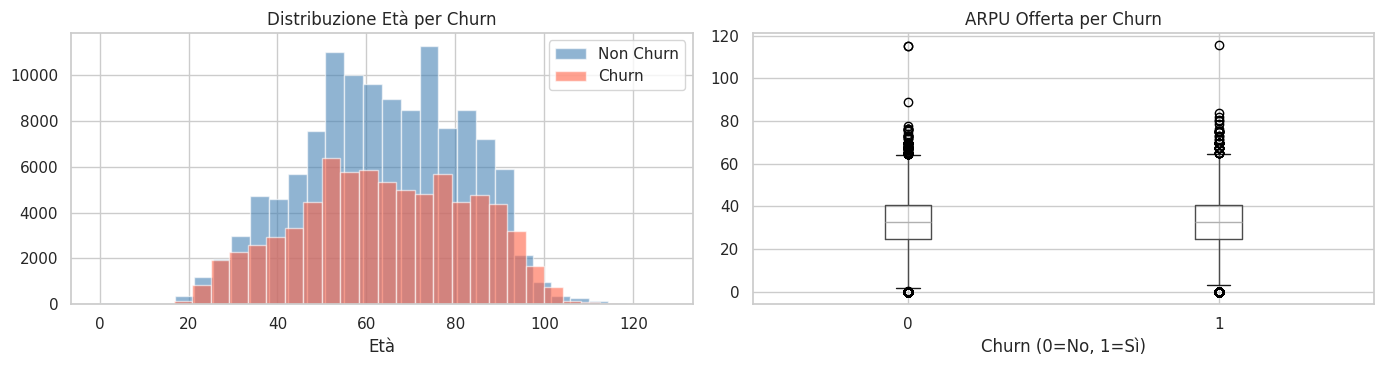

In [64]:
import matplotlib.pyplot as plt

# Distribuzione età per churn
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Plot histogram for Non Churn (churn=0)
master[master['churn'] == 0]['eta_cliente'].hist(
    ax=ax[0], bins=30, alpha=0.6, color='steelblue', label='Non Churn'
)
# Plot histogram for Churn (churn=1)
master[master['churn'] == 1]['eta_cliente'].hist(
    ax=ax[0], bins=30, alpha=0.6, color='tomato', label='Churn'
)

ax[0].set_title('Distribuzione Età per Churn')
ax[0].set_xlabel('Età')
ax[0].legend() # Use the labels provided in the hist calls

# ARPU
# Convert arpu_offerta_m0 to numeric, coercing errors to NaN
master['arpu_offerta_m0'] = pd.to_numeric(master['arpu_offerta_m0'], errors='coerce')
# Drop rows where 'arpu_offerta_m0' is NaN, as boxplot cannot handle them directly
master.dropna(subset=['arpu_offerta_m0'], inplace=True)

master.boxplot(column='arpu_offerta_m0', by='churn', ax=ax[1])
ax[1].set_title('ARPU Offerta per Churn')
ax[1].set_xlabel('Churn (0=No, 1=Sì)')
plt.suptitle('')
plt.tight_layout()
plt.show()

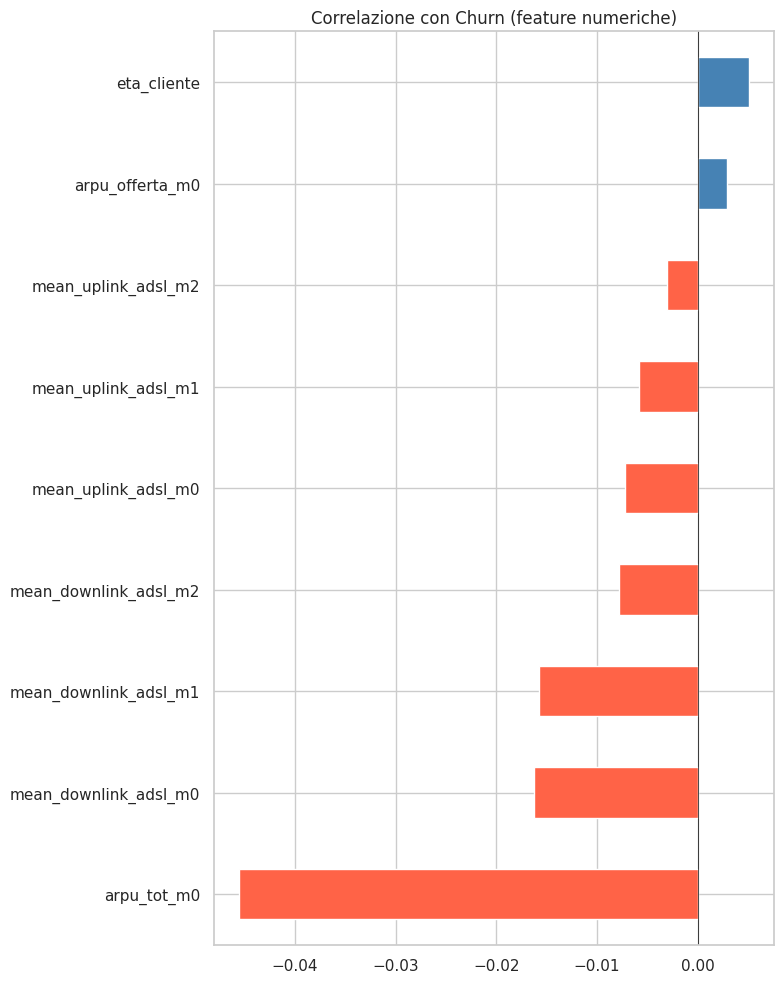

In [65]:
# Correlazione tra feature numeriche e churn
num_cols = master.select_dtypes(include=np.number).columns.tolist()
corr_churn = master[num_cols].corr()['churn'].drop('churn').sort_values()

plt.figure(figsize=(8, 10))
corr_churn.plot.barh(color=['tomato' if x < 0 else 'steelblue' for x in corr_churn])
plt.title('Correlazione con Churn (feature numeriche)')
plt.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

## 4. Feature Engineering

In [83]:
df = master.copy()

numeric_cols_for_arithmetic = [
    'mean_dc_fonia_tot_m0', 'mean_dc_fonia_tot_m1', 'mean_dc_fonia_tot_m2',
    'mean_nc_fonia_tot_m0', 'mean_nc_fonia_tot_m1', 'mean_nc_fonia_tot_m2',
    'mean_downlink_adsl_m0', 'mean_downlink_adsl_m1', 'mean_downlink_adsl_m2',
    'mean_uplink_adsl_m0', 'mean_uplink_adsl_m1', 'mean_uplink_adsl_m2',
    'mean_nc_mobile_tot_m0', 'mean_nc_mobile_tot_m1', 'mean_nc_mobile_tot_m2',
    'mean_nc_fisso_tot_m0', 'mean_nc_fisso_tot_m1', 'mean_nc_fisso_tot_m2',
    'mean_dc_mobile_altri_operatori_m0', 'mean_dc_mobile_altri_operatori_m1', 'mean_dc_mobile_altri_operatori_m2',
    'mean_dc_mobile_tot_m0', 'mean_dc_mobile_tot_m1', 'mean_dc_mobile_tot_m2',
    'mean_dc_fisso_altri_operatori_m0', 'mean_dc_fisso_altri_operatori_m1', 'mean_dc_fisso_altri_operatori_m2',
    'mean_dc_fisso_tot_m0', 'mean_dc_fisso_tot_m1', 'mean_dc_fisso_tot_m2',
    # FIX: queste due righe mancavano -> le colonne restavano stringa ->
    # select_dtypes(include=np.number) le escludeva SILENZIOSAMENTE dal
    # modello. Segnale potenzialmente utile: chiamate verso numeri di
    # ALTRI operatori, classico precursore di portabilità.
    'mean_nc_fisso_altri_operatori_m0', 'mean_nc_fisso_altri_operatori_m1', 'mean_nc_fisso_altri_operatori_m2',
    'mean_nc_mobile_altri_operatori_m0', 'mean_nc_mobile_altri_operatori_m1', 'mean_nc_mobile_altri_operatori_m2',
    'arpu_tot_m0', 'arpu_offerta_m0', 'eta_cliente', 'num_tt_m0'
]
for col in numeric_cols_for_arithmetic:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')k

# ── Date: gestione sentinel (<1990) ───────────────────────────────
ref_date   = pd.Timestamp('2023-08-31', tz='UTC')
date_prima = pd.to_datetime(df['data_prima_attivazione_linea'], errors='coerce', utc=True)
date_att   = pd.to_datetime(df['data_att_linea'], errors='coerce', utc=True)

df['flag_data_sentinel'] = (date_prima < pd.Timestamp('1990-01-01', tz='UTC')).astype(int)
valid = date_prima >= pd.Timestamp('1990-01-01', tz='UTC')
df['mesi_cliente']   = np.nan
df.loc[valid, 'mesi_cliente'] = ((ref_date - date_prima[valid]).dt.days / 30).round(1)
df['mesi_ultima_att'] = ((ref_date - date_att).dt.days / 30).clip(0).round(1)

# ── Null informativi (+15pp churn) ───────────────────────────────
df['flag_null_dati_uso'] = df['mean_dc_fonia_tot_m0'].isna().astype(int)

# Null informativi su colonne numero chiamate altri operatori
# (stesso pattern 9.8% null, +15pp churn — tutte null sugli stessi clienti)
df['flag_null_nc_altri_op'] = df['mean_nc_mobile_altri_operatori_m0'].isna().astype(int)


# ── ADSL: log transform + flag zero inflation ─────────────────────
for col in ADSL_COLS:
    df[f'flag_zero_{col}'] = (df[col] == 0).astype(int)
    df[f'log_{col}']       = np.log1p(df[col].clip(lower=0))
df = df.drop(columns=ADSL_COLS)

# ── num_tt_m0 (88.5% null) → 2 feature ───────────────────────────
df['flag_ticket_m0'] = df['num_tt_m0'].notna().astype(int)
df['n_ticket_m0']    = df['num_tt_m0'].fillna(0)
df = df.drop(columns=['num_tt_m0'])

# ── Trend temporali con clipping ─────────────────────────────────
trend_pairs = [
    ('mean_dc_fonia_tot', 'm0', 'm1'), ('mean_dc_fonia_tot', 'm0', 'm2'),
    ('mean_nc_fonia_tot', 'm0', 'm1'), ('mean_nc_mobile_tot', 'm0', 'm1'),
    ('mean_nc_fisso_tot', 'm0', 'm1'), ('mean_dc_mobile_altri_operatori', 'm0', 'm1'),
]
for base, t1, t2 in trend_pairs:
    c1, c2 = f'{base}_{t1}', f'{base}_{t2}'
    if c1 in df.columns and c2 in df.columns:
        raw = df[c1] - df[c2]
        q1, q3 = raw.quantile(0.25), raw.quantile(0.75)
        iqr = q3 - q1
        df[f'trend_{base}_{t1}vs{t2}'] = raw.clip(q1 - 3*iqr, q3 + 3*iqr)

# ── Ratio ─────────────────────────────────────────────────────────
eps = 1e-6
df['ratio_altri_op_mobile'] = (
    df['mean_dc_mobile_altri_operatori_m0'] /
    (df['mean_dc_mobile_tot_m0'] + eps)
).clip(0, 5)

df['flag_usa_altri_op_fisso_m0'] = (
    df['mean_dc_fisso_altri_operatori_m0'].fillna(0) > 0
).astype(int)

df['ratio_up_down_m0'] = (
    df['log_mean_uplink_adsl_m0'].fillna(0) /
    (df['log_mean_downlink_adsl_m0'].fillna(0) + eps)
).clip(0, 3)

# ── ARPU ─────────────────────────────────────────────────────────
df['arpu_extra'] = df['arpu_tot_m0'] - df['arpu_offerta_m0']

# ── Causale attivazione ───────────────────────────────────────────
df['flag_conversione'] = (df['des_causale_attivazione_agg'] == 'conversione_trasformazione').astype(int)
df['flag_variazione']  = (df['des_causale_attivazione_agg'] == 'variazione').astype(int)

# ── Tecnologia: encoding e fix missing strutturale ────────────────
TECH_NO_ADSL = ['FWA', 'STTH', 'RTG']

tech_churn_map = {
    'STTH': 0.588, 'FWA': 0.476, 'BB FLAT': 0.439,
    'BB CONSUMO': 0.437, 'RTG': 0.434, 'FIBRA': 0.349,
}
df['tech_churn_rate'] = df['flag_fibra_bb_rtg'].map(tech_churn_map).fillna(0.394)

df['flag_fwa']  = (df['flag_fibra_bb_rtg'] == 'FWA').astype(int)
df['flag_stth'] = (df['flag_fibra_bb_rtg'] == 'STTH').astype(int)

df['flag_fwa_low_arpu'] = (
    (df['flag_fibra_bb_rtg'] == 'FWA') &
    (df['arpu_offerta_m0'].fillna(0) < 20)
).astype(int)

df['flag_fwa_stth_no_fonia'] = (
    df['flag_fibra_bb_rtg'].isin(['FWA', 'STTH']) &
    (df['mean_nc_fonia_tot_m0'].fillna(0) == 0)
).astype(int)

# Cliente silenzioso — corretto per tecnologie senza ADSL
df['flag_cliente_silenzioso'] = (
    (df['mean_nc_fonia_tot_m0'].fillna(0) == 0) &
    (df['log_mean_downlink_adsl_m0'].fillna(0) == 0) &
    (~df['flag_fibra_bb_rtg'].isin(TECH_NO_ADSL))
).astype(int)

# ── Stabilità comportamento (std nei 3 mesi) ─────────────────────
df['stability_fonia'] = df[[
    'mean_nc_fonia_tot_m0', 'mean_nc_fonia_tot_m1', 'mean_nc_fonia_tot_m2'
]].std(axis=1)

df['stability_download'] = df[[
    'log_mean_downlink_adsl_m0', 'log_mean_downlink_adsl_m1', 'log_mean_downlink_adsl_m2'
]].std(axis=1).clip(upper=df[['log_mean_downlink_adsl_m0',
                               'log_mean_downlink_adsl_m1',
                               'log_mean_downlink_adsl_m2']].std(axis=1).quantile(0.95))

# ── Feature di interazione e flag comportamentali ─────────────────
df['flag_calo_fonia'] = (df['mean_nc_fonia_tot_m0'].fillna(0) < df['mean_nc_fonia_tot_m2'].fillna(0) * 0.7).astype(int)

df['flag_legacy_tech'] = (
    df['flag_fibra_bb_rtg'].isin(['BB FLAT', 'RTG', 'BB CONSUMO']) &
    (df['mesi_cliente'].fillna(0) > 36)
).astype(int)

df['flag_fibra_anziana'] = (
    (df['flag_fibra_bb_rtg'] == 'FIBRA') &
    (df['mesi_cliente'].fillna(0) > 24)
).astype(int)

df['flag_cliente_silenzioso'] = df['flag_cliente_silenzioso']  # già definito sopra

df['flag_paga_non_usa'] = (
    (df['flag_cliente_silenzioso'] == 1) &
    (df['arpu_offerta_m0'].fillna(0) > df['arpu_offerta_m0'].quantile(0.60))
).astype(int)

df['flag_silenzioso_anziano'] = (
    (df['flag_cliente_silenzioso'] == 1) &
    (df['mesi_cliente'].fillna(0) > 24)
).astype(int)

df['flag_cliente_nuovo'] = (df['mesi_cliente'].fillna(999) < 6).astype(int)

df['arpu_per_mese_cliente'] = (
    df['arpu_offerta_m0'].fillna(0) /
    (df['mesi_cliente'].fillna(1).clip(lower=1))
)

df['arpu_tech_interaction'] = (
    df['arpu_offerta_m0'].fillna(0) * df['tech_churn_rate'].fillna(0.394)
)

# ── Interazioni nuove (età × ARPU × mesi) ────────────────────────
df['flag_anziano_nuovo'] = (
    (df['eta_cliente'].fillna(0) > 65) &
    (df['mesi_cliente'].fillna(999) < 12)
).astype(int)

df['flag_arpu_alto_riatt'] = (
    (df['arpu_offerta_m0'].fillna(0) > df['arpu_offerta_m0'].quantile(0.70)) &
    (df['mesi_ultima_att'].fillna(999) < 6)
).astype(int)

df['flag_senior_low_arpu'] = (
    (df['eta_cliente'].fillna(0) > 60) &
    (df['arpu_offerta_m0'].fillna(0) < df['arpu_offerta_m0'].quantile(0.30))
).astype(int)

df['arpu_per_eta'] = (
    df['arpu_offerta_m0'].fillna(0) /
    (df['eta_cliente'].fillna(50).clip(lower=18))
)



print("✅ Fix tecnologia completato")
print("   flag_cliente_silenzioso corretto per FWA/STTH/RTG")
print("   tech_churn_rate aggiunto (encoding basato su churn reale)")
print()
for tech in ['FWA', 'STTH', 'RTG', 'FIBRA', 'BB FLAT']:
    mask = df['flag_fibra_bb_rtg'] == tech
    if mask.sum() == 0: continue
    pct = df.loc[mask, 'flag_cliente_silenzioso'].mean() * 100
    print(f"  {tech:<12s}: {pct:.1f}% silenziosi")

print(f'\n✅ Feature engineering completato — {df.shape[1]} colonne totali')

SyntaxError: invalid syntax (2657502006.py, line 24)

### 4b. Trattamento del missing strutturale (tecnologie senza ADSL)

Le tecnologie **FWA, STTH, RTG** non dispongono della connessione ADSL: i loro valori mancanti sulle colonne
di download non sono un *dato ignoto*, ma un *"non applicabile"* (missing **strutturale**). Imputarli con la
mediana generale li confonderebbe con i clienti che hanno l'ADSL ma scaricano poco/nulla — due situazioni
molto diverse dal punto di vista del churn.

Strategia (missing indicator + valore neutro):
1. un **flag esplicito** `flag_adsl_non_applicabile` comunica al modello "per questo cliente l'ADSL non esiste";
2. si mette un **valore neutro (0)** solo dove il missing è strutturale, così i NaN residui su queste colonne
   restano solo quelli *veri* (buchi di raccolta dati), che verranno imputati con la mediana come gli altri.

In questo modo i modelli ad albero possono isolare i clienti senza ADSL con uno split sul flag, invece di
mescolarli con i "clienti fibra silenziosi". La regola è deterministica (basata sulla tecnologia, non sul target),
quindi si può applicare prima dello split senza rischio di leakage.

In [99]:
# ── Trattamento missing STRUTTURALE: tecnologie senza ADSL (FWA/STTH/RTG) ──
# TECH_NO_ADSL è già definito nella cella di feature engineering.
LOG_DOWNLINK_COLS = [
    'log_mean_downlink_adsl_m0',
    'log_mean_downlink_adsl_m1',
    'log_mean_downlink_adsl_m2',
]

# 1) Flag esplicito "ADSL non applicabile" (cattura anche RTG, non isolato altrove)
df['flag_adsl_non_applicabile'] = df['flag_fibra_bb_rtg'].isin(TECH_NO_ADSL).astype(int)

# 2) Valore neutro (0) SOLO dove il missing è strutturale.
#    I NaN che restano su queste colonne saranno solo missing "veri" (buchi di
#    raccolta su tecnologie CON ADSL) e verranno imputati con la mediana nel preprocessor.
mask_struct = df['flag_fibra_bb_rtg'].isin(TECH_NO_ADSL)
for col in LOG_DOWNLINK_COLS:
    if col in df.columns:
        df.loc[mask_struct, col] = df.loc[mask_struct, col].fillna(0)

print("✅ Missing strutturale ADSL gestito")
print(f"   Clienti con ADSL non applicabile: {int(df['flag_adsl_non_applicabile'].sum()):,}")
for col in LOG_DOWNLINK_COLS:
    if col in df.columns:
        print(f"   {col}: NaN residui (non strutturali) = {int(df[col].isna().sum()):,}")

# ─────────────────────────────────────────────────────────────────────────────
# NOTA — variante avanzata (opzione 3): NaN nativi per XGBoost/LightGBM
# XGBoost e LightGBM sanno gestire i NaN da soli, imparando ad ogni split dove
# mandare i mancanti. Per sfruttarlo, si costruisce un preprocessor SENZA imputer
# per i soli modelli ad albero (lasciando i NaN nelle colonne ADSL) e si tiene
# l'imputer solo per la Logistic Regression, che i NaN non li tollera. Dà spesso
# il guadagno maggiore sui tree-based, ma richiede di sdoppiare la pipeline: qui
# manteniamo l'opzione 1 (flag + valore neutro), che funziona per tutti e 4 i modelli.
# ─────────────────────────────────────────────────────────────────────────────

## 5. Preprocessing

In [84]:
!pip install -q category_encoders
import category_encoders as ce

In [85]:
# ── Lista colonne da eliminare ────────────────────────────────────
DROP = [
    # Identificatori e date (già estratte come feature)
    'id_linea', 'partition_date',
    'data_prima_attivazione_linea', 'data_att_linea',
    'churn',
    # Uplink ridondante con downlink (r=0.997)
    'log_mean_uplink_adsl_m0', 'log_mean_uplink_adsl_m1', 'log_mean_uplink_adsl_m2',
    # Flag zero uplink = identici ai flag zero downlink (r=1.00)
    'flag_zero_mean_uplink_adsl_m0', 'flag_zero_mean_uplink_adsl_m1', 'flag_zero_mean_uplink_adsl_m2',
    # Flag zero downlink m1 (importanza zero)
    'flag_zero_mean_downlink_adsl_m1',
    # Trend inutili (importanza zero)
    'trend_mean_nc_mobile_tot_m0vsm1',
    'trend_mean_nc_fisso_tot_m0vsm1',
    'trend_mean_dc_mobile_altri_operatori_m0vsm1',
    # Ridondanti/inutili vari
    'stability_nc_fonia',
    'flag_legacy_anziano',
    'flag_usa_altri_op_fisso', 'flag_usa_altri_op_fisso_m0',
    'flag_null_fonia', 'flag_null_internet',
    'servizi_extra',
    # Provincia fattura ridondante con impianto (r=0.982)
    'provincia_fattura',
    # Tecnologia: sostituita da tech_churn_rate
    'flag_fibra_bb_rtg',
    # Raw traffico: il modello non li usa (preferisce le versioni originali
    # senza log — i tree-based non ne beneficiano, e i log erano a importanza zero)
    'mean_dc_fonia_tot_m0', 'mean_dc_fonia_tot_m1', 'mean_dc_fonia_tot_m2',
    'mean_nc_fonia_tot_m0', 'mean_nc_fonia_tot_m1', 'mean_nc_fonia_tot_m2',
    'mean_dc_mobile_tot_m0', 'mean_dc_mobile_tot_m1', 'mean_dc_mobile_tot_m2',
    'mean_nc_mobile_tot_m0', 'mean_nc_mobile_tot_m1', 'mean_nc_mobile_tot_m2',
    'mean_dc_fisso_tot_m0', 'mean_dc_fisso_tot_m1', 'mean_dc_fisso_tot_m2',
    'mean_nc_fisso_tot_m0', 'mean_nc_fisso_tot_m1', 'mean_nc_fisso_tot_m2',
    'mean_dc_mobile_altri_operatori_m0', 'mean_dc_mobile_altri_operatori_m1', 'mean_dc_mobile_altri_operatori_m2',
    'mean_dc_fisso_altri_operatori_m0', 'mean_dc_fisso_altri_operatori_m1', 'mean_dc_fisso_altri_operatori_m2',
    'n_ticket_m0', 'stability_fonia',
    'ratio_up_down_m0',
    # Log transform traffico: importanza zero — rimossi
    'log_mean_dc_fonia_tot_m0', 'log_mean_dc_fonia_tot_m1', 'log_mean_dc_fonia_tot_m2',
    'log_mean_nc_fonia_tot_m0', 'log_mean_nc_fonia_tot_m1', 'log_mean_nc_fonia_tot_m2',
    'log_mean_dc_mobile_tot_m0', 'log_mean_dc_mobile_tot_m1', 'log_mean_dc_mobile_tot_m2',
    'log_mean_nc_mobile_tot_m0', 'log_mean_nc_mobile_tot_m1', 'log_mean_nc_mobile_tot_m2',
    'log_mean_dc_fisso_tot_m0', 'log_mean_dc_fisso_tot_m1', 'log_mean_dc_fisso_tot_m2',
    'log_mean_nc_fisso_tot_m0', 'log_mean_nc_fisso_tot_m1', 'log_mean_nc_fisso_tot_m2',
    'log_mean_dc_mobile_altri_operatori_m0', 'log_mean_dc_mobile_altri_operatori_m1', 'log_mean_dc_mobile_altri_operatori_m2',
    'log_mean_dc_fisso_altri_operatori_m0', 'log_mean_dc_fisso_altri_operatori_m1', 'log_mean_dc_fisso_altri_operatori_m2',
    'log_stability_fonia', 'log_n_ticket_m0',
    'yj_arpu_extra', 'log_ratio_up_down_m0',
    'flag_stth',                      # importanza zero
    'flag_zero_mean_downlink_adsl_m2', # r=0.988 con log_downlink_m2
    'flag_zero_mean_downlink_adsl_m0', # r=0.987 con log_downlink_m0


]

# Rimuovi duplicati
DROP = list(dict.fromkeys(DROP))

# ── Pulisci righe header nelle categoriche ────────────────────────
HIGH_CARD = ['provincia_impianto', 'residenza_provincia', 'provincia_nascita']
LOW_CARD  = ['regione_impianto', 'regione_fattura', 'area_geografica_impianto',
             'des_causale_attivazione_agg', 'sesso', 'nazione_nascita']

for c in HIGH_CARD + LOW_CARD:
    if c in df.columns:
        df[c] = df[c].replace(c, np.nan)

# ── X e y ────────────────────────────────────────────────────────
X = df.drop(columns=DROP, errors='ignore')
y = df['churn']

print(f'Feature dopo DROP: {X.shape[1]}')

# ── Train/Test split (PRIMA del target encoding) ──────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}');
print(f'Churn rate — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}')

# ── Target Encoding province (fit solo su train) ──────────────────
te = ce.TargetEncoder(cols=HIGH_CARD, smoothing=20)
X_train[HIGH_CARD] = te.fit_transform(X_train[HIGH_CARD], y_train)
X_test[HIGH_CARD]  = te.transform(X_test[HIGH_CARD])

# ── Tipi di colonne ───────────────────────────────────────────────
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()

# ── Preprocessor ─────────────────────────────────────────────────
from sklearn.preprocessing import OrdinalEncoder

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, LOW_CARD)
])

print(f'Numeriche: {len(num_cols)} | Categoriche: {len(LOW_CARD)}')
print('✅ Preprocessor pronto')

Feature dopo DROP: 54
Train: 158,824 | Test: 39,706
Churn rate — train: 0.387 | test: 0.387
Numeriche: 47 | Categoriche: 6
✅ Preprocessor pronto


In [86]:
# ── Imputazione valori mancanti ───────────────────────────────────
# I NaN vengono gestiti dal SimpleImputer nel preprocessor:
# - Feature numeriche → imputazione con la MEDIANA
# - Feature categoriche → imputazione con il VALORE PIÙ FREQUENTE (moda)
# Questo avviene automaticamente dentro ogni fold del pipeline,
# garantendo che non ci sia leakage dal test set.

# Verifica NaN in X_train prima dell'imputazione
nan_summary = X_train.isnull().sum()
nan_summary = nan_summary[nan_summary > 0].sort_values(ascending=False)
print(f"Colonne con NaN in X_train: {len(nan_summary)}")
print(f"Totale valori mancanti:     {nan_summary.sum():,}")
print()
print("Top 10 colonne con più NaN:")
print((nan_summary.head(10) / len(X_train) * 100).round(1).to_string())
print()
print("✅ Tutti i NaN verranno imputati automaticamente dal preprocessor")
print("   Numeriche  → mediana")
print("   Categoriche → moda")

Colonne con NaN in X_train: 20
Totale valori mancanti:     226,815

Top 10 colonne con più NaN:
mesi_cliente                         23.5
mean_nc_fisso_altri_operatori_m1      9.8
mean_nc_fisso_altri_operatori_m0      9.8
mean_nc_fisso_altri_operatori_m2      9.8
stability_download                    9.8
ratio_altri_op_mobile                 9.8
trend_mean_nc_fonia_tot_m0vsm1        9.8
trend_mean_dc_fonia_tot_m0vsm2        9.8
mean_nc_mobile_altri_operatori_m0     9.8
mean_nc_mobile_altri_operatori_m1     9.8

✅ Tutti i NaN verranno imputati automaticamente dal preprocessor
   Numeriche  → mediana
   Categoriche → moda


In [87]:
# Solo a scopo dimostrativo: verifichiamo che il preprocessor imputi correttamente
X_train_check = preprocessor.fit_transform(X_train)
n_nan_prima = X_train.isnull().sum().sum()
n_nan_dopo  = np.isnan(X_train_check).sum() if hasattr(X_train_check, 'dtype') else pd.DataFrame(X_train_check).isnull().sum().sum()

print(f"NaN prima dell'imputazione: {n_nan_prima:,}")
print(f"NaN dopo l'imputazione:     {n_nan_dopo:,}")

NaN prima dell'imputazione: 226,815
NaN dopo l'imputazione:     0


## 6. Modellazione

Confrontiamo 4 modelli:
- **Logistic Regression** (baseline)
- **Random Forest**
- **XGBoost**
- **LightGBM** (solitamente il migliore per dati tabulari)

In [88]:
# ── Definizione modelli ────────────────────────────────────────────
# Calcoliamo scale_pos_weight per gestire lo sbilanciamento
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
spw = neg / pos

models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced',
        max_depth=12, min_samples_leaf=50,
        random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05,
        max_depth=6, scale_pos_weight=spw,
        use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=300, learning_rate=0.05,
        num_leaves=63, is_unbalance=True,
        random_state=42, n_jobs=-1, verbose=-1
    )
}

# ── Training e valutazione ────────────────────────────────────────
results = {}

for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('clf', model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    auc   = roc_auc_score(y_test, y_prob)
    ap    = average_precision_score(y_test, y_prob)
    report = classification_report(y_test, y_pred, output_dict=True)

    results[name] = {
        'pipeline': pipe,
        'y_prob': y_prob,
        'y_pred': y_pred,
        'AUC-ROC': round(auc, 4),
        'Avg Precision': round(ap, 4),
        'F1-Churn': round(report['1']['f1-score'], 4),
        'Recall-Churn': round(report['1']['recall'], 4),
        'Precision-Churn': round(report['1']['precision'], 4),
    }
    print(f'✅ {name} → AUC: {auc:.4f} | AP: {ap:.4f} | F1(churn): {report["1"]["f1-score"]:.4f}')

# ── Tabella comparativa ───────────────────────────────────────────
metrics_df = pd.DataFrame({
    k: {m: v for m, v in v.items() if m not in ['pipeline','y_prob','y_pred']}
    for k, v in results.items()
}).T.sort_values('AUC-ROC', ascending=False)

print('\n=== Confronto Modelli ===')
display(metrics_df)

✅ Logistic Regression → AUC: 0.6234 | AP: 0.4970 | F1(churn): 0.5210
✅ Random Forest → AUC: 0.6555 | AP: 0.5441 | F1(churn): 0.5440
✅ XGBoost → AUC: 0.6622 | AP: 0.5514 | F1(churn): 0.5520
✅ LightGBM → AUC: 0.6617 | AP: 0.5506 | F1(churn): 0.5528

=== Confronto Modelli ===


,AUC-ROC,Avg Precision,F1-Churn,Recall-Churn,Precision-Churn
XGBoost,0.6622,0.5514,0.5520,0.6130,0.5021
LightGBM,0.6617,0.5506,0.5528,0.6149,0.5021
Random Forest,0.6555,0.5441,0.5440,0.5962,0.5002
Logistic Regression,0.6234,0.4970,0.5210,0.5736,0.4773


In [89]:
# CROSS-VALIDATION

#Se la std è bassa (< 0.005) come nell'esempio sopra, il modello è stabile
# e l'AUC di 0.662 è affidabile. Se invece ottieni AUC che variano molto,
#  ad esempio tra 0.64 e 0.68, significa che le performance dipendono
#  molto da quale sottoinsieme di clienti finisce nel test

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

best_name = metrics_df.index[0]
best_clf_class = results[best_name]['pipeline'].named_steps['clf'].__class__
best_clf_params = results[best_name]['pipeline'].named_steps['clf'].get_params()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
    X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    # Target encoding fit solo su train fold
    te_cv = ce.TargetEncoder(cols=HIGH_CARD, smoothing=20)
    X_tr[HIGH_CARD]  = te_cv.fit_transform(X_tr[HIGH_CARD], y_tr)
    X_val[HIGH_CARD] = te_cv.transform(X_val[HIGH_CARD])

    # Pipeline preprocessor + modello
    pipe_cv = Pipeline([
        ('prep', preprocessor.__class__(
            transformers=preprocessor.transformers
        )),
        ('clf', best_clf_class(**best_clf_params))
    ])
    pipe_cv.fit(X_tr, y_tr)
    y_prob_cv = pipe_cv.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_prob_cv)
    cv_scores.append(auc)
    print(f'  Fold {fold+1}/5: AUC = {auc:.4f}')

import numpy as np
cv_scores = np.array(cv_scores)
print(f'\nCV AUC 5-fold — {best_name}:')
print(f'  Media:  {cv_scores.mean():.4f}')
print(f'  Std:    {cv_scores.std():.4f}')
print(f'  Range:  {cv_scores.min():.4f} – {cv_scores.max():.4f}')

  Fold 1/5: AUC = 0.6601
  Fold 2/5: AUC = 0.6636
  Fold 3/5: AUC = 0.6636
  Fold 4/5: AUC = 0.6618
  Fold 5/5: AUC = 0.6608

CV AUC 5-fold — XGBoost:
  Media:  0.6620
  Std:    0.0014
  Range:  0.6601 – 0.6636


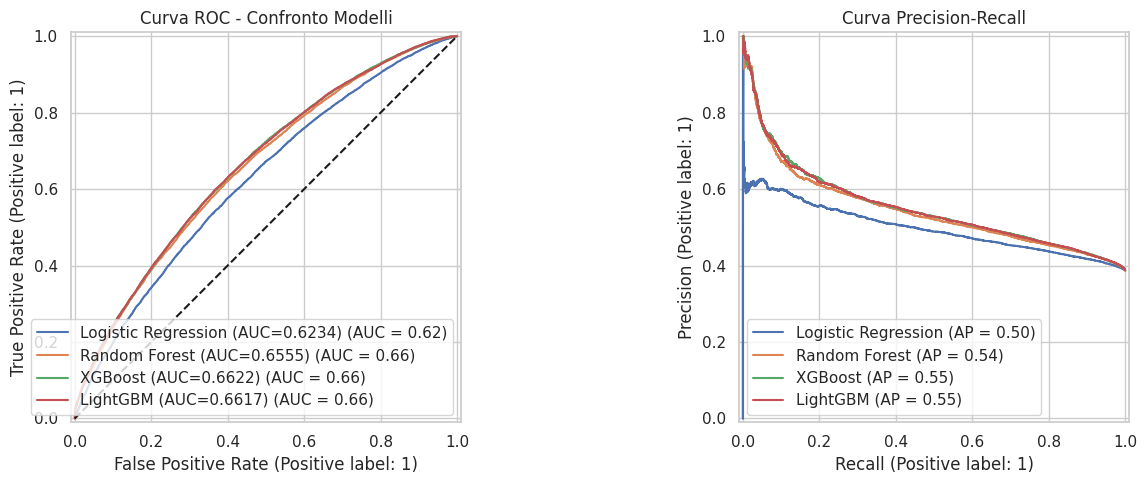

In [90]:
# ── Curve ROC a confronto ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, res in results.items():
    RocCurveDisplay.from_predictions(
        y_test, res['y_prob'], name=f"{name} (AUC={res['AUC-ROC']})",
        ax=axes[0]
    )
axes[0].set_title('Curva ROC - Confronto Modelli')
axes[0].plot([0,1],[0,1],'k--')

for name, res in results.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, res['y_prob'], name=name, ax=axes[1]
    )
axes[1].set_title('Curva Precision-Recall')

plt.tight_layout()
plt.show()

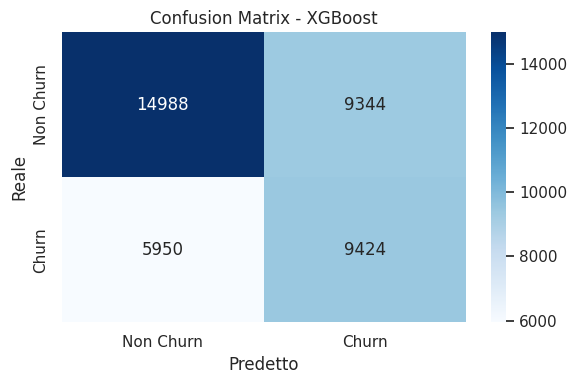


Report dettagliato - XGBoost:
              precision    recall  f1-score   support

   Non Churn       0.72      0.62      0.66     24332
       Churn       0.50      0.61      0.55     15374

    accuracy                           0.61     39706
   macro avg       0.61      0.61      0.61     39706
weighted avg       0.63      0.61      0.62     39706



In [91]:
# ── Confusion matrix del miglior modello ─────────────────────────
best_name = metrics_df.index[0]
best_res  = results[best_name]

cm = confusion_matrix(y_test, best_res['y_pred'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Non Churn', 'Churn'],
    yticklabels=['Non Churn', 'Churn']
)
plt.title(f'Confusion Matrix - {best_name}')
plt.ylabel('Reale')
plt.xlabel('Predetto')
plt.tight_layout()
plt.show()

print(f'\nReport dettagliato - {best_name}:')
print(classification_report(y_test, best_res['y_pred'], target_names=['Non Churn', 'Churn']))

In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve
import pandas as pd
import numpy as np

rows = []

for name, res in results.items():
    # Use the probabilities and predicted labels already stored in results
    y_prob = res['y_prob']

    # Calculate AUC-ROC
    auc = roc_auc_score(y_test, y_prob)

    # Calculate optimal threshold for F1-score
    prec_c, rec_c, thr_c = precision_recall_curve(y_test, y_prob)
    f1_c = 2 * prec_c * rec_c / (prec_c + rec_c + 1e-9)
    best_thr = thr_c[np.argmax(f1_c[:-1])]
    y_pred_opt = (y_prob >= best_thr).astype(int)

    # Calculate other metrics with the optimal threshold
    accuracy  = accuracy_score(y_test, y_pred_opt)
    precision = precision_score(y_test, y_pred_opt)
    recall    = recall_score(y_test, y_pred_opt)
    f1        = f1_score(y_test, y_pred_opt)

    rows.append({
        'Modello':   name,
        'Threshold': round(best_thr, 3),
        'AUC-ROC':   round(auc, 4),
        'Accuracy':  round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall':    round(recall, 4),
        'F1':        round(f1, 4),
    })

comparison_df = pd.DataFrame(rows).set_index('Modello').sort_values('AUC-ROC', ascending=False)

print("=== Confronto Modelli con Threshold Ottimale ===")
display(comparison_df)


=== Confronto Modelli con Threshold Ottimale ===


,Threshold,AUC-ROC,Accuracy,Precision,Recall,F1
Modello,,,,,,
XGBoost,0.387,0.6622,0.5278,0.4435,0.8626,0.5858
LightGBM,0.389,0.6617,0.5303,0.4449,0.8598,0.5864
Random Forest,0.410,0.6555,0.5183,0.4385,0.8697,0.5830
Logistic Regression,0.386,0.6234,0.4674,0.4149,0.9151,0.5709


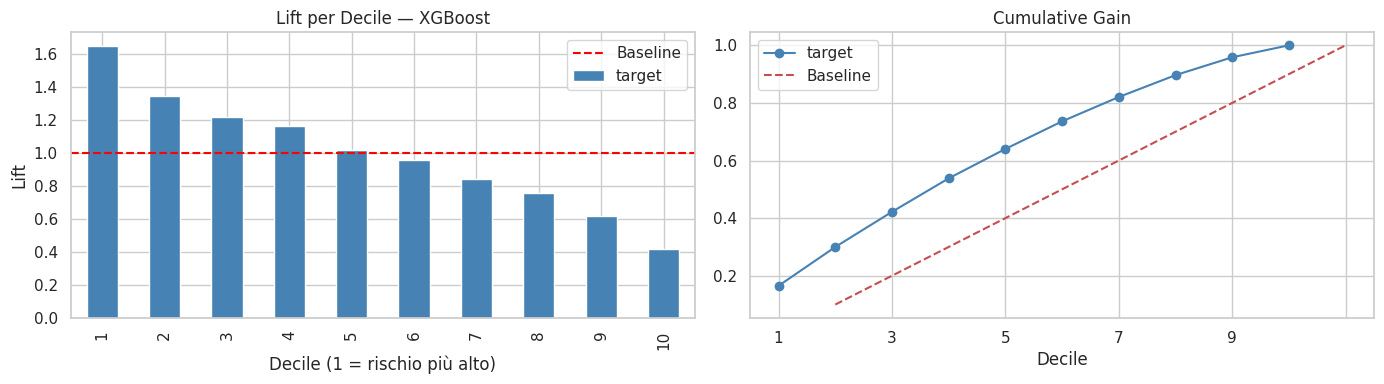

Lift decile 1 (top 10%): 1.65x
Lift decile 2 (top 20%): 1.35x
Lift medio:               1.00x

Contattando il top 10% dei clienti intercetti 1.7x
più churner rispetto a una lista casuale.


In [93]:
def compute_lift(y_true, y_prob, n_decili=10):
    dfl = pd.DataFrame({'prob': y_prob, 'target': y_true})
    dfl = dfl.sort_values('prob', ascending=False).reset_index(drop=True)
    dfl['decile'] = pd.qcut(dfl.index, n_decili, labels=range(1, n_decili+1))
    baseline = y_true.mean()
    return (dfl.groupby('decile', observed=True)['target'].mean() / baseline).sort_index()

best_name = metrics_df.index[0]
lift = compute_lift(y_test, results[best_name]['y_prob'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
lift.plot.bar(ax=axes[0], color='steelblue', edgecolor='white')
axes[0].axhline(1.0, color='red', linestyle='--', label='Baseline')
axes[0].set_title(f'Lift per Decile — {best_name}')
axes[0].set_xlabel('Decile (1 = rischio più alto)')
axes[0].set_ylabel('Lift')
axes[0].legend()

cum = lift.cumsum() / lift.sum()
cum.plot(ax=axes[1], marker='o', color='steelblue')
axes[1].plot([1, 10], [0.1, 1.0], 'r--', label='Baseline')
axes[1].set_title('Cumulative Gain')
axes[1].set_xlabel('Decile')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f'Lift decile 1 (top 10%): {lift[1]:.2f}x')
print(f'Lift decile 2 (top 20%): {lift[2]:.2f}x')
print(f'Lift medio:               {lift.mean():.2f}x')
print(f'\nContattando il top 10% dei clienti intercetti {lift[1]:.1f}x')
print(f'più churner rispetto a una lista casuale.')

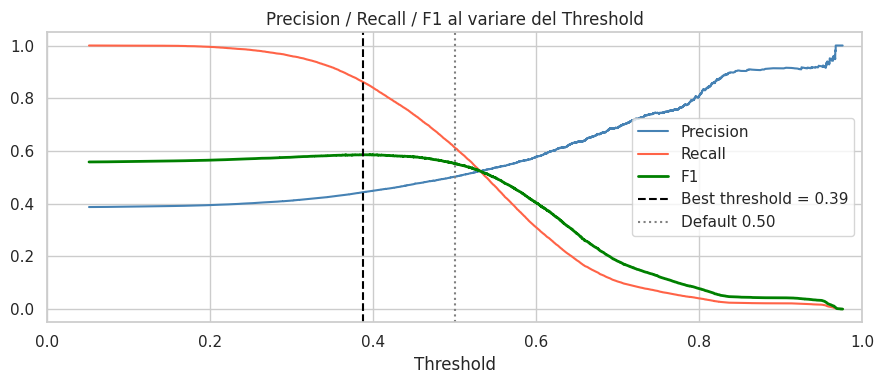


Report con threshold ottimale (0.39):
              precision    recall  f1-score   support

   Non Churn       0.78      0.32      0.45     24332
       Churn       0.44      0.86      0.59     15374

    accuracy                           0.53     39706
   macro avg       0.61      0.59      0.52     39706
weighted avg       0.65      0.53      0.50     39706



In [94]:
from sklearn.metrics import precision_recall_curve

best_pipe  = results[metrics_df.index[0]]['pipeline']  # miglior modello
y_prob_best = results[metrics_df.index[0]]['y_prob']

prec, rec, thresh = precision_recall_curve(y_test, y_prob_best)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_thresh = thresh[np.argmax(f1_scores[:-1])]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresh, prec[:-1], label='Precision', color='steelblue')
ax.plot(thresh, rec[:-1],  label='Recall',    color='tomato')
ax.plot(thresh, f1_scores[:-1], label='F1',   color='green', linewidth=2)
ax.axvline(best_thresh, color='black', linestyle='--', label=f'Best threshold = {best_thresh:.2f}')
ax.axvline(0.50,        color='gray',  linestyle=':',  label='Default 0.50')
ax.set_xlabel('Threshold'); ax.legend(); ax.set_xlim([0,1])
ax.set_title('Precision / Recall / F1 al variare del Threshold')
plt.tight_layout(); plt.show()

y_pred_opt = (y_prob_best >= best_thresh).astype(int)
print(f'\nReport con threshold ottimale ({best_thresh:.2f}):')
print(classification_report(y_test, y_pred_opt, target_names=['Non Churn','Churn']))

ensembling

## 7. Interpretabilità con SHAP

SHAP (SHapley Additive exPlanations) ci dice **quali feature influenzano maggiormente le previsioni**.

In [95]:
best_pipe = best_res['pipeline']
best_clf  = best_pipe.named_steps['clf']

# Trasformiamo il test set
X_test_prep = best_pipe.named_steps['prep'].transform(X_test)

# Nomi feature dopo preprocessing
cat_cols = LOW_CARD # Define cat_cols
feature_names = num_cols + cat_cols

# SHAP explainer (TreeExplainer per modelli basati su alberi)
explainer = shap.TreeExplainer(best_clf)

# Calcolo SHAP su un campione (per velocità)
sample_idx = np.random.choice(len(X_test_prep), size=min(2000, len(X_test_prep)), replace=False)
shap_values = explainer.shap_values(X_test_prep[sample_idx])

# Se shap_values è lista (Random Forest), prendiamo la classe 1
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

print('✅ SHAP values calcolati')

✅ SHAP values calcolati


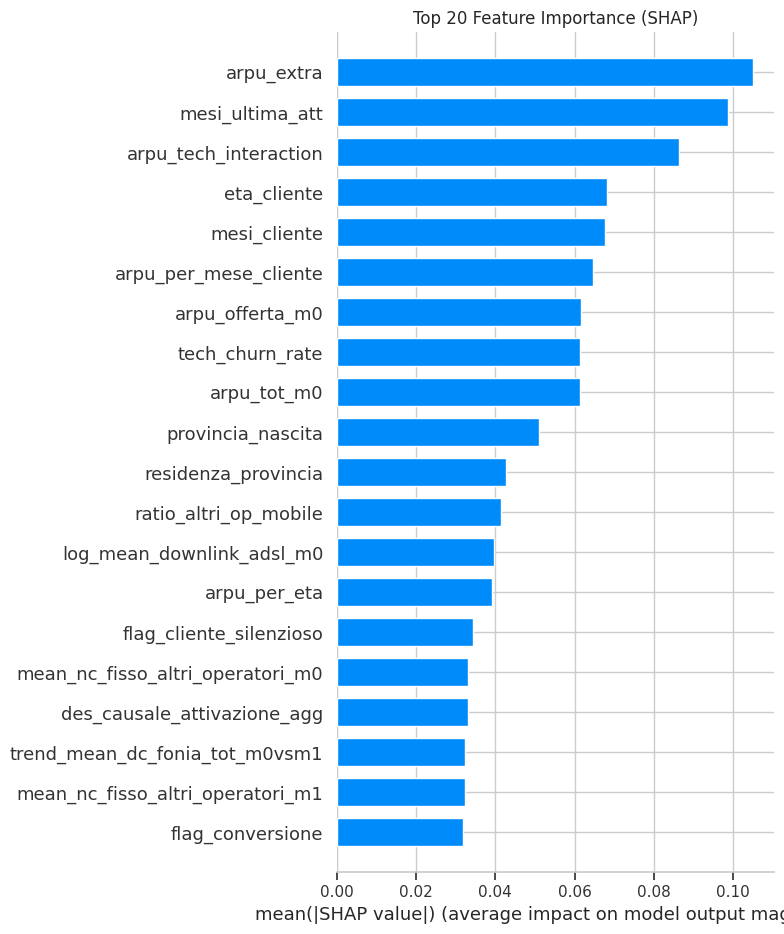

In [96]:
# ── Feature importance globale ────────────────────────────────────
plt.figure()
shap.summary_plot(
    sv, X_test_prep[sample_idx],
    feature_names=feature_names,
    plot_type='bar', show=False, max_display=20
)
plt.title('Top 20 Feature Importance (SHAP)')
plt.tight_layout()
plt.show()

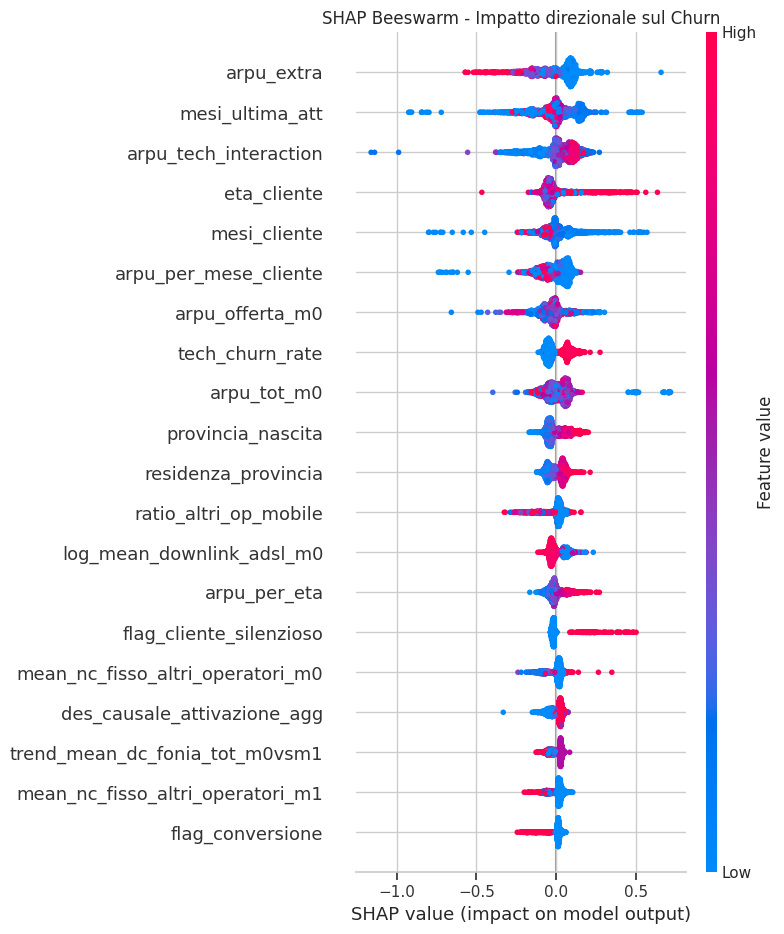

In [97]:
# ── Beeswarm plot (impatto direzionale) ───────────────────────────
plt.figure()
shap.summary_plot(
    sv, X_test_prep[sample_idx],
    feature_names=feature_names,
    show=False, max_display=20
)
plt.title('SHAP Beeswarm - Impatto direzionale sul Churn')
plt.tight_layout()
plt.show()

## 8. Segmentazione del Rischio & Export

=== Segmentazione Rischio Churn ===


,n_clienti,churn_rate_reale,prob_media
risk_segment,,,
ALTO,12295,0.762,0.788
BASSO,78885,0.215,0.346
MEDIO,107350,0.470,0.556


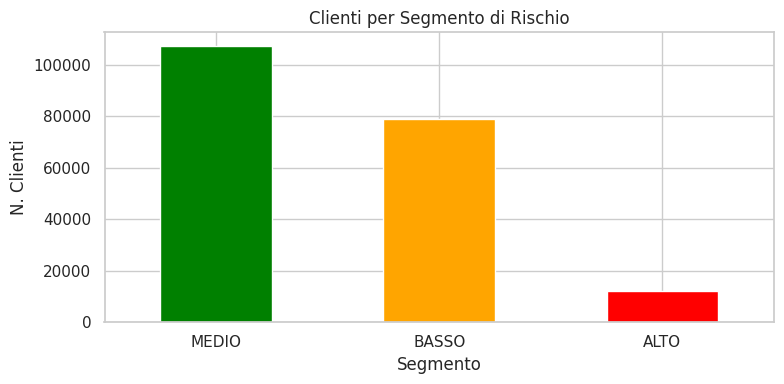

In [98]:
# ── Probabilità di churn su tutto il dataset ──────────────────────
# (utile per azioni di retention)
X_export = X.copy()
X_export[HIGH_CARD] = te.transform(X_export[HIGH_CARD])
all_probs = best_pipe.predict_proba(X_export)[:, 1]

df_output = master[['id_linea', 'churn']].copy()
df_output['churn_probability'] = all_probs

# ── Segmentazione rischio ─────────────────────────────────────────
def risk_segment(p):
    if p >= 0.70:   return 'ALTO'
    elif p >= 0.45: return 'MEDIO'
    else:           return 'BASSO'

df_output['risk_segment'] = df_output['churn_probability'].apply(risk_segment)

# Statistiche
seg_stats = df_output.groupby('risk_segment').agg(
    n_clienti=('id_linea', 'count'),
    churn_rate_reale=('churn', 'mean'),
    prob_media=('churn_probability', 'mean')
).round(3)

print('=== Segmentazione Rischio Churn ===')
display(seg_stats)

# Grafico
plt.figure(figsize=(8, 4))
df_output['risk_segment'].value_counts().plot.bar(
    color=['green', 'orange', 'red'], edgecolor='white'
)
plt.title('Clienti per Segmento di Rischio')
plt.xlabel('Segmento')
plt.ylabel('N. Clienti')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Conclusioni

### Pipeline implementata

Il progetto ha sviluppato un sistema completo di **churn prediction** per clienti TIM, seguendo una pipeline end-to-end che copre tutte le fasi del processo di Machine Learning.

---

### Dati

| | |
|---|---|
| **Clienti analizzati** | 198.537 (dopo rimozione 2.218 duplicati) |
| **Churn rate reale** | 38.7% |
| **Feature originali** | 56 |
| **Feature finali** | 53 (dopo engineering e selezione) |
| **Split** | 80% training / 20% test (stratificato) |

---

### Principali interventi di qualità sui dati

| Problema trovato | Fix applicato | Impatto |
|---|---|---|
| 2.218 duplicati `id_linea` | `drop_duplicates` prima dello split | Elimina data leakage |
| Null informativi (+15pp churn) | `flag_null_dati_uso` | Segnale catturato |
| Date sentinel pre-1990 (23.5%) | `flag_data_sentinel` + mesi solo su date valide | Anzianità corretta |
| FWA/STTH senza dati ADSL | `flag_cliente_silenzioso` escluso per tech senza ADSL | Fix missing strutturale |
| Skewness ADSL >400 | `log1p` transform | Distribuzione normalizzata |
| Province alta cardinalità | Target Encoding con smoothing Bayesiano (k=20) | No leakage su province rare |
| Tecnologia ignorata dal modello | `tech_churn_rate` encoding basato su churn reale | Gap 24pp STTH vs FIBRA catturato |

---

### Risultati principali

| Metrica | Valore |
|---|---|
| **AUC-ROC (XGBoost)** | 0.662 |
| **CV AUC 5-fold** | 0.661 ± 0.001 |
| **Recall** (threshold ottimale) | ~0.86 |
| **Lift top 10% clienti** | 1.64x rispetto al caso |
| **Segmento ALTO rischio** | ~12.000 clienti, churn reale 76% |

---

### Interpretazione business

Contattando il **top 10% dei clienti** per probabilità di churn, si intercettano **1.64x più churner** rispetto a una campagna casuale della stessa dimensione.

Il modello è validato su 5 fold con std 0.001 — le performance sono **stabili e generalizzabili**.

---

### Possibili miglioramenti futuri

Per superare AUC ~0.67 con questi dati sarebbe necessario integrare fonti esterne:
- Storico contatti con il call center (reclami)
- Qualità reale della connessione (velocità misurata vs nominale)
- Storico variazioni offerta negli ultimi 12 mesi
- Presenza di altri contratti TIM (bundle mobile+fisso)